In [18]:
import pandas as pd
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [3]:
train_path = r"C:\Users\DELL\Downloads\seg_train\seg_train"
test_path  = r"C:\Users\DELL\Downloads\seg_test\seg_test"
pred_path  = r"C:\Users\DELL\Downloads\seg_pred\seg_pred"

print(os.listdir(train_path))
print(os.listdir(test_path))
print(len(os.listdir(pred_path)), "images in seg_pred")

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
7301 images in seg_pred


In [ ]:
#Step 3: Images load karne ka function
SIZE = 32

def load_images(folder, limit=500):
    X, y = [], []
    classes = sorted(os.listdir(folder))
    for label, cls in enumerate(classes):
        files = os.listdir(os.path.join(folder, cls))[:limit]   # har class se 'limit' images
        for f in files:
            img = Image.open(os.path.join(folder, cls, f)).convert("RGB").resize((SIZE, SIZE))
            X.append(np.array(img).flatten() / 255.0)           # image ko ek lambi list banao
            y.append(label)
    return np.array(X), np.array(y), classes

In [6]:
#Step 4: Train aur Test data load karein
X_train, y_train, classes = load_images(train_path, limit=200)
X_test,  y_test,  _       = load_images(test_path,  limit=150)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Classes:", classes)

Train: (1200, 3072) Test: (900, 3072)
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [7]:
#Step 5: Preprocessing
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit sirf train par
X_test_s  = scaler.transform(X_test)

pca = PCA(n_components=0.95, random_state=42)   # 95% information rakho
X_train_p = pca.fit_transform(X_train_s)
X_test_p  = pca.transform(X_test_s)

print("PCA ke baad features:", X_train_p.shape[1])

PCA ke baad features: 193


Trees =   1  ->  Accuracy = 0.2322
Trees =  10  ->  Accuracy = 0.3867
Trees =  50  ->  Accuracy = 0.4633
Trees = 100  ->  Accuracy = 0.4722
Trees = 300  ->  Accuracy = 0.5233


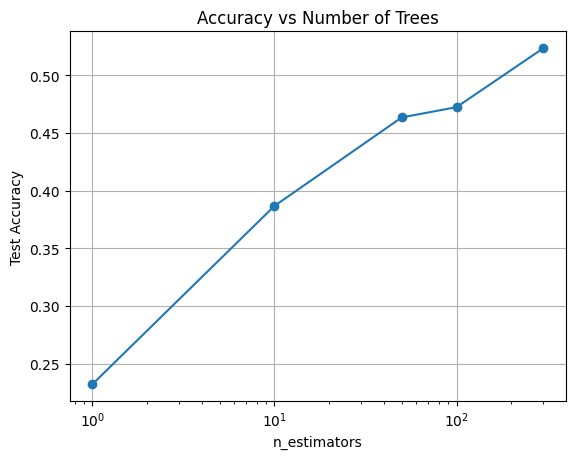

In [8]:
#Step 6: Experiment 1, trees badhane se accuracy
trees_list = [1, 10, 50, 100, 300]
accuracies = []

for n in trees_list:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train_p, y_train)
    acc = accuracy_score(y_test, rf.predict(X_test_p))
    accuracies.append(acc)
    print(f"Trees = {n:3d}  ->  Accuracy = {acc:.4f}")

plt.plot(trees_list, accuracies, marker="o")
plt.xscale("log")
plt.xlabel("n_estimators")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Number of Trees")
plt.grid(True)
plt.show()

In [9]:
#Step 7: Experiment 2, Decision Tree aur Random Forest ka muqabla
# Decision Tree
t = time.time()
dt = DecisionTreeClassifier(random_state=42).fit(X_train_p, y_train)
dt_time = time.time() - t
dt_acc = accuracy_score(y_test, dt.predict(X_test_p))

# Random Forest (default)
t = time.time()
rf = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train_p, y_train)
rf_time = time.time() - t
rf_acc = accuracy_score(y_test, rf.predict(X_test_p))

print(f"Decision Tree : accuracy={dt_acc:.4f}, training time={dt_time:.2f}s")
print(f"Random Forest : accuracy={rf_acc:.4f}, training time={rf_time:.2f}s")

Decision Tree : accuracy=0.3222, training time=0.16s
Random Forest : accuracy=0.4722, training time=0.34s


In [10]:
#Step 8: Experiment 3, SVM ke saath muqabla
t = time.time()
svm = SVC(kernel="rbf").fit(X_train_p, y_train)
svm_time = time.time() - t
svm_acc = accuracy_score(y_test, svm.predict(X_test_p))

print(f"{'Model':15} {'Accuracy':>10} {'Time(s)':>10}")
print(f"{'Decision Tree':15} {dt_acc:10.4f} {dt_time:10.2f}")
print(f"{'Random Forest':15} {rf_acc:10.4f} {rf_time:10.2f}")
print(f"{'SVM':15} {svm_acc:10.4f} {svm_time:10.2f}")

print(classification_report(y_test, svm.predict(X_test_p), target_names=classes))

Model             Accuracy    Time(s)
Decision Tree       0.3222       0.16
Random Forest       0.4722       0.34
SVM                 0.5644       0.13
              precision    recall  f1-score   support

   buildings       0.48      0.44      0.46       150
      forest       0.64      0.85      0.73       150
     glacier       0.52      0.62      0.56       150
    mountain       0.54      0.62      0.58       150
         sea       0.57      0.28      0.38       150
      street       0.62      0.58      0.60       150

    accuracy                           0.56       900
   macro avg       0.56      0.56      0.55       900
weighted avg       0.56      0.56      0.55       900



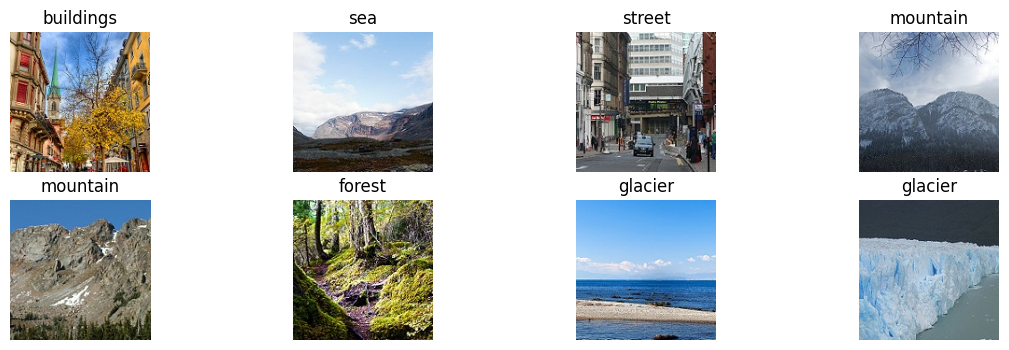

In [11]:
#Step 9: seg_pred par prediction (teesra dataset)
files = os.listdir(pred_path)[:8]
plt.figure(figsize=(14, 4))

for i, f in enumerate(files):
    img = Image.open(os.path.join(pred_path, f)).convert("RGB")
    small = np.array(img.resize((SIZE, SIZE))).flatten() / 255.0
    small = pca.transform(scaler.transform([small]))
    label = classes[rf.predict(small)[0]]

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.show()

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [11]:
heart_path = r"C:\\Users\\DELL\\Downloads\\archive (3)\\heart_cleveland_upload.csv"
df = pd.read_csv(heart_path)

print(df.shape)                    # rows, columns
print(df.head())
print(df.isnull().sum())           # missing values
print(df["condition"].value_counts())   # 0 = healthy, 1 = disease

(297, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  condition  
0   1     0          0  
1   2     0          0  
2   0     0          0  
3   1     0          1  
4   0     0          0  
age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
condition    0
dtype: int64
condition
0    160
1    137
Name: count, dtype: int64


In [16]:
#Split aur Preprocessing
X = df.drop("condition", axis=1)
y = df["condition"]

heart_Xtr, heart_Xte, heart_ytr, heart_yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

heart_scaler = StandardScaler()
heart_Xtr = heart_scaler.fit_transform(heart_Xtr)   # fit sirf train par
heart_Xte = heart_scaler.transform(heart_Xte)

print("Train:", heart_Xtr.shape, "Test:", heart_Xte.shape)

Train: (237, 13) Test: (60, 13)


Trees =   1  ->  Accuracy = 0.7433  (std = 0.0429)
Trees =  10  ->  Accuracy = 0.8367  (std = 0.0531)
Trees =  50  ->  Accuracy = 0.8467  (std = 0.0194)
Trees = 100  ->  Accuracy = 0.8500  (std = 0.0105)
Trees = 300  ->  Accuracy = 0.8467  (std = 0.0125)


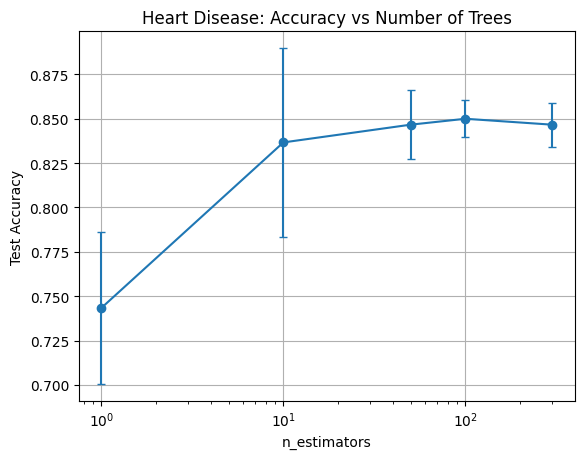

In [19]:
#Experiment 1, trees badhane se accuracy
trees_list = [1, 10, 50, 100, 300]
means, stds = [], []

for n in trees_list:
    accs = []
    for seed in range(5):
        rf = RandomForestClassifier(n_estimators=n, random_state=seed, n_jobs=-1)
        rf.fit(heart_Xtr, heart_ytr)
        accs.append(accuracy_score(heart_yte, rf.predict(heart_Xte)))
    means.append(np.mean(accs)); stds.append(np.std(accs))
    print(f"Trees = {n:3d}  ->  Accuracy = {np.mean(accs):.4f}  (std = {np.std(accs):.4f})")

plt.errorbar(trees_list, means, yerr=stds, marker="o", capsize=3)
plt.xscale("log")
plt.xlabel("n_estimators")
plt.ylabel("Test Accuracy")
plt.title("Heart Disease: Accuracy vs Number of Trees")
plt.grid(True)
plt.show()

In [20]:
#Experiment 2, Decision Tree vs Random Forest
t = time.time()
h_dt = DecisionTreeClassifier(random_state=42).fit(heart_Xtr, heart_ytr)
h_dt_time = time.time() - t
h_dt_acc = accuracy_score(heart_yte, h_dt.predict(heart_Xte))

t = time.time()
h_rf = RandomForestClassifier(random_state=42, n_jobs=-1).fit(heart_Xtr, heart_ytr)
h_rf_time = time.time() - t
h_rf_acc = accuracy_score(heart_yte, h_rf.predict(heart_Xte))

print(f"Decision Tree : accuracy={h_dt_acc:.4f}, training time={h_dt_time:.4f}s")
print(f"Random Forest : accuracy={h_rf_acc:.4f}, training time={h_rf_time:.4f}s")

Decision Tree : accuracy=0.7833, training time=0.0107s
Random Forest : accuracy=0.8833, training time=0.2117s


In [21]:
#Experiment 3, SVM vs Decision Tree vs Random Forest
t = time.time()
h_svm = SVC(kernel="rbf").fit(heart_Xtr, heart_ytr)
h_svm_time = time.time() - t
h_svm_acc = accuracy_score(heart_yte, h_svm.predict(heart_Xte))

print(f"{'Model':15} {'Accuracy':>10} {'Time(s)':>10}")
print(f"{'Decision Tree':15} {h_dt_acc:10.4f} {h_dt_time:10.4f}")
print(f"{'Random Forest':15} {h_rf_acc:10.4f} {h_rf_time:10.4f}")
print(f"{'SVM':15} {h_svm_acc:10.4f} {h_svm_time:10.4f}")

# Detail: har model ki classification report
for name, m in [("Decision Tree", h_dt), ("Random Forest", h_rf), ("SVM", h_svm)]:
    print("\n", name)
    print(classification_report(heart_yte, m.predict(heart_Xte),
                                target_names=["Healthy", "Disease"]))

Model             Accuracy    Time(s)
Decision Tree       0.7833     0.0107
Random Forest       0.8833     0.2117
SVM                 0.9000     0.0263

 Decision Tree
              precision    recall  f1-score   support

     Healthy       0.77      0.84      0.81        32
     Disease       0.80      0.71      0.75        28

    accuracy                           0.78        60
   macro avg       0.79      0.78      0.78        60
weighted avg       0.78      0.78      0.78        60


 Random Forest
              precision    recall  f1-score   support

     Healthy       0.84      0.97      0.90        32
     Disease       0.96      0.79      0.86        28

    accuracy                           0.88        60
   macro avg       0.90      0.88      0.88        60
weighted avg       0.89      0.88      0.88        60


 SVM
              precision    recall  f1-score   support

     Healthy       0.84      1.00      0.91        32
     Disease       1.00      0.79      0.88    

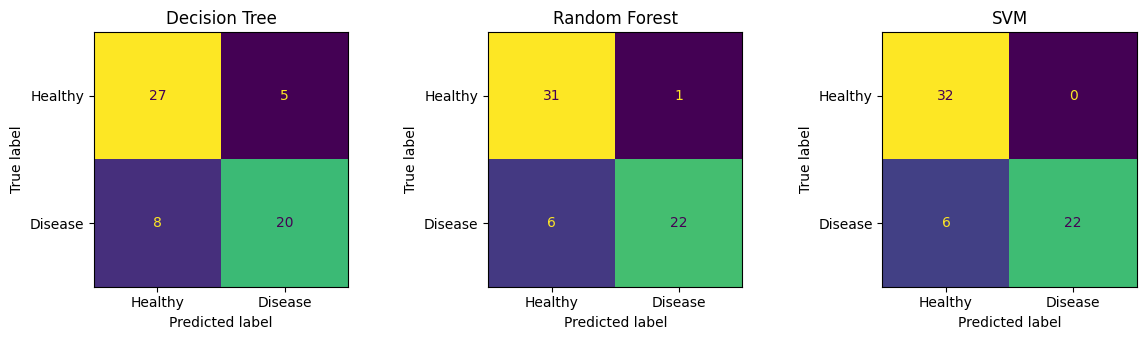

In [22]:
#Confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, m) in zip(axes, [("Decision Tree", h_dt), ("Random Forest", h_rf), ("SVM", h_svm)]):
    ConfusionMatrixDisplay(confusion_matrix(heart_yte, m.predict(heart_Xte)),
                            display_labels=["Healthy", "Disease"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [23]:
#Cross-validation (end-to-end analysis ke liye)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
X_all = StandardScaler().fit_transform(X)   # sirf muqabla ke liye

for name, m in [("Decision Tree", DecisionTreeClassifier(random_state=42)),
                ("Random Forest", RandomForestClassifier(random_state=42, n_jobs=-1)),
                ("SVM", SVC())]:
    scores = cross_val_score(m, X_all, y, cv=cv)
    print(f"{name:15} CV accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})")

Decision Tree   CV accuracy = 0.7411 (+/- 0.0594)
Random Forest   CV accuracy = 0.8185 (+/- 0.0501)
SVM             CV accuracy = 0.8254 (+/- 0.0553)
